# Feature Validation & Unsupervised Clustering (clinical_data.csv)

**Scope:** Leakage-safe feature relevance ranking via Mutual Information, unsupervised cluster selection (`K-Means` and `GMM` across $k = 2 \dots 8$ evaluated with Silhouette Score, Adjusted Rand Index, Normalized Mutual Information, BIC, and AIC), contingency comparison at $k=6$ against true `diagnostic` labels (`NEV`, `ACK`, `SEK`, `BCC`, `SCC`, `MEL`), and 2D PCA structure inspection on `final_train.csv`.

## 1. Environment Setup & Artifact Loading
All exploratory and unsupervised analyses are conducted strictly on the patient-grouped training partition (`final_train.csv`) and `feature_metadata.json` produced by the preprocessing stage, preventing test-set information leakage. All tables and figures are saved under `../Output/02_fe_unsupervised/`.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.feature_selection import mutual_info_classif

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

In [ ]:


cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "src-code" else cwd

SEED = 42
SAVE = True
DATA_DIR = Path("../Dataset/modelling")
OUT_DIR = PROJECT_ROOT / "Output" / "02_fe_unsupervised"
if SAVE:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {OUT_DIR.resolve()}")

train_df = pd.read_csv(DATA_DIR / "final_train.csv")
with open(DATA_DIR / "feature_metadata.json", encoding="utf-8") as f:
    meta = json.load(f)

feature_cols = meta["feature_cols"]
LABELS = meta["labels"]
X_train = train_df[feature_cols]
y_train = train_df["y_multiclass"].values

print(f"Loaded training split: {X_train.shape[0]} samples, {len(feature_cols)} features, {len(LABELS)} classes.")

Output directory: C:\Users\Administrator\Desktop\skin-project\Output\02_fe_unsupervised
Loaded training split: 1827 samples, 79 features, 6 classes.


## 2. Feature Relevance via Mutual Information (Training Split)
We apply median imputation on `X_train` and compute non-parametric Mutual Information (`mutual_info_classif`) against `y_multiclass` to quantify dependency between clinical/engineered/missingness indicators and diagnostic categories.

In [2]:
X_imp = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X_train),
    columns=feature_cols,
    index=X_train.index,
)
mi_scores = mutual_info_classif(X_imp, y_train, random_state=SEED)
mi_df = (
    pd.DataFrame({"feature": feature_cols, "mutual_info": mi_scores})
    .sort_values("mutual_info", ascending=False)
    .reset_index(drop=True)
)

print("=== Top 15 Features by Mutual Information (Train) ===")
print(mi_df.head(15).round(4).to_string(index=False))

if SAVE:
    mi_df.to_csv(OUT_DIR / "feature_mutual_info.csv", index=False)

=== Top 15 Features by Mutual Information (Train) ===
                    feature  mutual_info
                    biopsed       0.4161
                   log_area       0.3631
             age_x_symptoms       0.3565
  background_mother_MISSING       0.3426
             gender_MISSING       0.3422
        fitspatrick_missing       0.3382
          has_questionnaire       0.3360
             diameter_ratio       0.3350
     cancer_history_MISSING       0.3290
skin_cancer_history_MISSING       0.3252
    has_piped_water_MISSING       0.3222
              smoke_MISSING       0.3183
  background_father_MISSING       0.3162
           diameter_missing       0.3133
          pesticide_MISSING       0.3122


## 3. Unsupervised Clustering & Model Selection
After standardizing features (`StandardScaler`), we evaluate **K-Means** (partition-based) and **Gaussian Mixture Models** (probabilistic EM with full covariance) across $k = 2 to 8$. Internal compactness/separation is measured via Silhouette Score and information criteria (`BIC`, `AIC`), while external alignment with true `y_multiclass` labels is reported via `ARI` and `NMI` for diagnostic interpretation.

 k  kmeans_silhouette  kmeans_ari  kmeans_nmi      gmm_bic      gmm_aic  gmm_ari  gmm_nmi
 2             0.2673      0.2516      0.2991 -544073.8994 -579775.9790   0.2516   0.2991
 3             0.2597      0.2109      0.2851 -643364.3327 -696920.2073   0.2665   0.2847
 4             0.2300      0.1847      0.2630 -674011.9187 -745421.5882   0.2170   0.2527
 5             0.2309      0.1755      0.2524 -683549.9432 -772813.4078   0.1968   0.2338
 6             0.2288      0.1732      0.2404 -668386.3537 -775503.6133   0.1700   0.2252
 7             0.2328      0.1732      0.2405 -686781.5505 -811752.6051   0.2162   0.2317
 8             0.0997      0.2133      0.2751 -704586.3388 -847411.1884   0.2227   0.2352


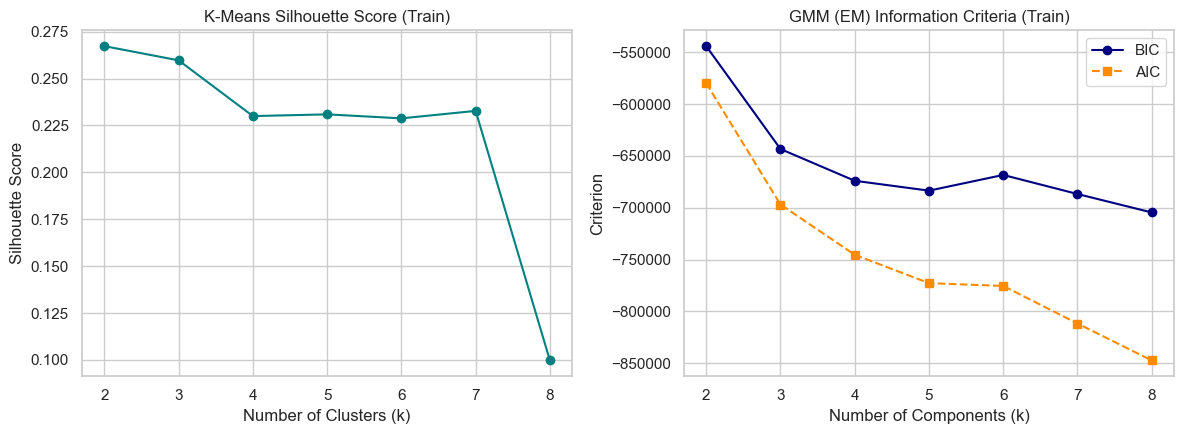

In [3]:
X_scaled = StandardScaler().fit_transform(X_imp)

cluster_rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    km_labels = km.fit_predict(X_scaled)

    gmm = GaussianMixture(n_components=k, covariance_type="full", n_init=5, random_state=SEED)
    gmm_labels = gmm.fit_predict(X_scaled)

    cluster_rows.append({
        "k": k,
        "kmeans_silhouette": silhouette_score(X_scaled, km_labels),
        "kmeans_ari": adjusted_rand_score(y_train, km_labels),
        "kmeans_nmi": normalized_mutual_info_score(y_train, km_labels),
        "gmm_bic": gmm.bic(X_scaled),
        "gmm_aic": gmm.aic(X_scaled),
        "gmm_ari": adjusted_rand_score(y_train, gmm_labels),
        "gmm_nmi": normalized_mutual_info_score(y_train, gmm_labels),
    })

cluster_sel_df = pd.DataFrame(cluster_rows)
print(cluster_sel_df.round(4).to_string(index=False))

if SAVE:
    cluster_sel_df.to_csv(OUT_DIR / "clustering_selection.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(cluster_sel_df["k"], cluster_sel_df["kmeans_silhouette"], "o-", color="teal")
axes[0].set_title("K-Means Silhouette Score (Train)")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Silhouette Score")

axes[1].plot(cluster_sel_df["k"], cluster_sel_df["gmm_bic"], "o-", label="BIC", color="navy")
axes[1].plot(cluster_sel_df["k"], cluster_sel_df["gmm_aic"], "s--", label="AIC", color="darkorange")
axes[1].set_title("GMM (EM) Information Criteria (Train)")
axes[1].set_xlabel("Number of Components (k)")
axes[1].set_ylabel("Criterion")
axes[1].legend()
plt.tight_layout()

if SAVE:
    fig.savefig(OUT_DIR / "clustering_model_selection.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Six-Cluster ($k=6$) Contingency Analysis & 2D PCA Structure
To examine how unsupervised clusters correspond to the six clinical diagnostic classes (`NEV`, `ACK`, `SEK`, `BCC`, `SCC`, `MEL`), we inspect the cross-tabulation at $k=6$ and project the standardized feature space onto the first two principal components (`PCA`).

=== Cluster (k=6) vs True Diagnosis ===
diagnostic  NEV  ACK  SEK  BCC  SCC  MEL
Cluster_k6                              
0            11   65   14  175   18   14
1           127  361  154    0    0    0
2             1   18    5   49   15    0
3            17   64   11   91   27   19
4             4   60    4  157   38    6
5            30    2    7  198   60    5


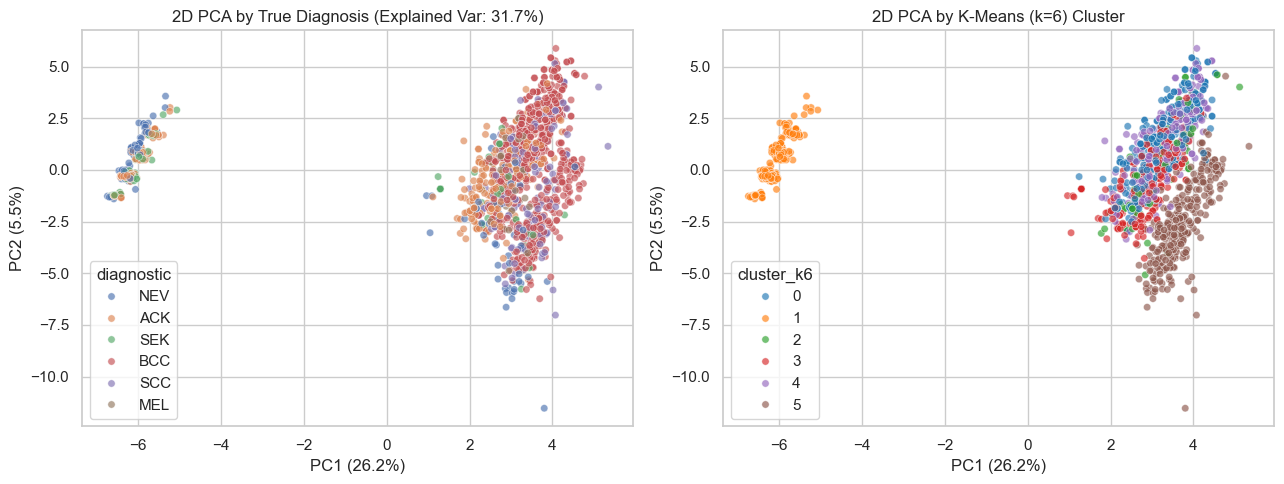

In [4]:
km_6 = KMeans(n_clusters=6, n_init=20, random_state=SEED)
clusters_k6 = km_6.fit_predict(X_scaled)

diag_series = pd.Series(train_df["diagnostic"].values, name="diagnostic")
cluster_series = pd.Series(clusters_k6, name="Cluster_k6")
ct_k6 = pd.crosstab(cluster_series, diag_series)[LABELS]

print("=== Cluster (k=6) vs True Diagnosis ===")
print(ct_k6)

if SAVE:
    ct_k6.to_csv(OUT_DIR / "cluster_k6_vs_diagnosis.csv")

pca = PCA(n_components=2, random_state=SEED)
coords_2d = pca.fit_transform(X_scaled)
evr = pca.explained_variance_ratio_

pca_df = pd.DataFrame({
    "PC1": coords_2d[:, 0],
    "PC2": coords_2d[:, 1],
    "diagnostic": train_df["diagnostic"].values,
    "cluster_k6": clusters_k6,
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="diagnostic", hue_order=LABELS, alpha=0.65, s=28, ax=axes[0])
axes[0].set_title(f"2D PCA by True Diagnosis (Explained Var: {evr.sum():.1%})")
axes[0].set_xlabel(f"PC1 ({evr[0]:.1%})")
axes[0].set_ylabel(f"PC2 ({evr[1]:.1%})")

sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="cluster_k6", palette="tab10", alpha=0.65, s=28, ax=axes[1])
axes[1].set_title("2D PCA by K-Means (k=6) Cluster")
axes[1].set_xlabel(f"PC1 ({evr[0]:.1%})")
axes[1].set_ylabel(f"PC2 ({evr[1]:.1%})")

plt.tight_layout()
if SAVE:
    fig.savefig(OUT_DIR / "pca_k6_comparison.png", dpi=300, bbox_inches="tight")
plt.show()